## 1. Importimi i Librariave të Nevojshme

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

# Konfigurimi i stil-it për vizualizim
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Ngarkimi i Datasetit

In [2]:
# Ngarkimi i datasetit
df = pd.read_csv('insurance.csv')

# Shfaqja e dimensionit të datasetit
print(f"Dimensioni i datasetit: {df.shape}")
print(f"\nNumri i rreshtave: {df.shape[0]}")
print(f"Numri i kolonave: {df.shape[1]}")

Dimensioni i datasetit: (1338, 7)

Numri i rreshtave: 1338
Numri i kolonave: 7


## 3. Eksplorimi Bazik i të Dhënave (EDA)

In [41]:
# Shfaqja e 5 rreshtave të parë
print("Pesë rreshtat e parë:")
print(df.head())

# Informacion rreth datasetit
print("\nInformimet e datasetit:")
df.info()

Pesë rreshtat e parë:
   age     sex   bmi  children smoker     region  expenses
0   19  female  27.9         0    yes  southwest  16884.92
1   18    male  33.8         1     no  southeast   1725.55
2   28    male  33.0         3     no  southeast   4449.46
3   33    male  22.7         0     no  northwest  21984.47
4   32    male  28.9         0     no  northwest   3866.86

Informimet e datasetit:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [11]:
# Statistika përshkruese
print("Statistika përshkruese:")
print(df.describe())

Statistika përshkruese:
               age          bmi     children      expenses
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.665471     1.094918  13270.422414
std      14.049960     6.098382     1.205493  12110.011240
min      18.000000    16.000000     0.000000   1121.870000
25%      27.000000    26.300000     0.000000   4740.287500
50%      39.000000    30.400000     1.000000   9382.030000
75%      51.000000    34.700000     2.000000  16639.915000
max      64.000000    53.100000     5.000000  63770.430000


In [12]:
# Kontrollimi i vlerave të munguara
print("Vlerat e munguara:")
print(df.isnull().sum())
print(f"\nPërqindja e vlerave të munguara: {(df.isnull().sum() / len(df) * 100).round(2)}%")

Vlerat e munguara:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64

Përqindja e vlerave të munguara: age         0.0
sex         0.0
bmi         0.0
children    0.0
smoker      0.0
region      0.0
expenses    0.0
dtype: float64%


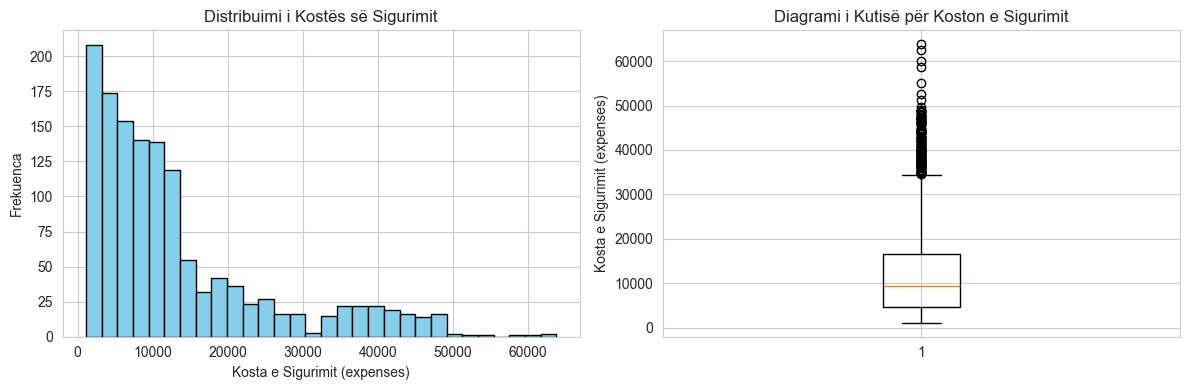

Mesatarja: 13270.42
Mediana: 9382.03
Devijimi standard: 12110.01


In [35]:
# Analiza e distribuimit të ndryshores target (expenses)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df['expenses'], bins=30, edgecolor='black', color='skyblue')
plt.xlabel('Kosta e Sigurimit (expenses)')
plt.ylabel('Frekuenca')
plt.title('Distribuimi i Kostës së Sigurimit')

plt.subplot(1, 2, 2)
plt.boxplot(df['expenses'])
plt.ylabel('Kosta e Sigurimit (expenses)')
plt.title('Diagrami i Kutisë për Koston e Sigurimit')

plt.tight_layout()
plt.show()

print(f"Mesatarja: {df['expenses'].mean():.2f}")
print(f"Mediana: {df['expenses'].median():.2f}")
print(f"Devijimi standard: {df['expenses'].std():.2f}")

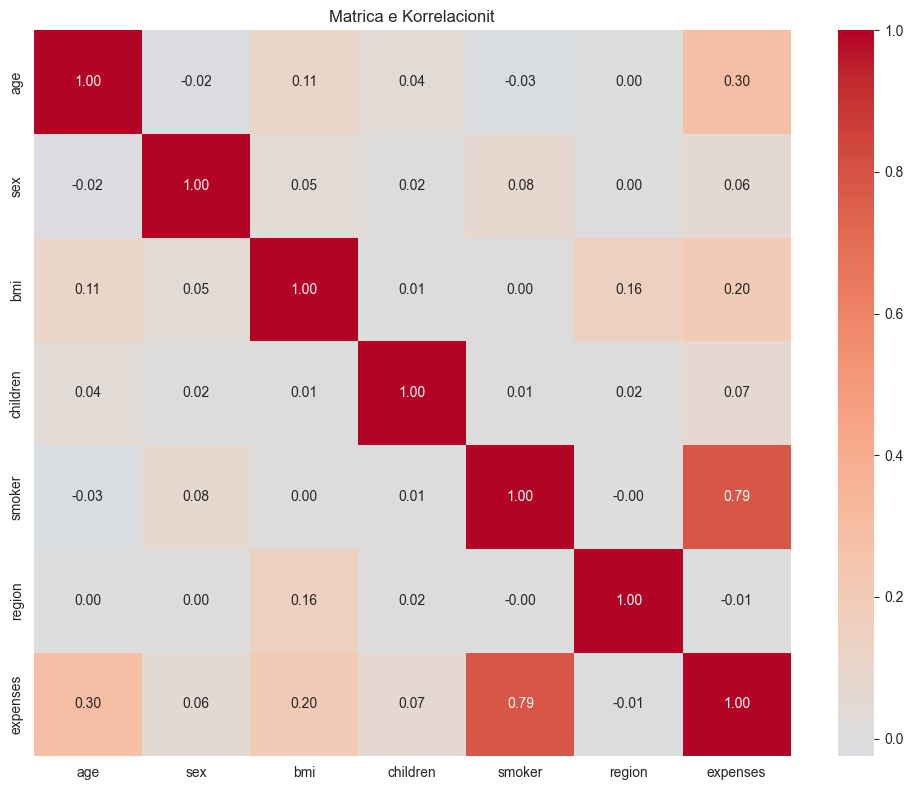

In [34]:
# Korelacioni midis ndryshoreve
# Fillimisht, konvertojmë variablat kategorikë në numrikë për korrelacionin
df_corr = df.copy()
le = LabelEncoder()
for col in df_corr.select_dtypes(include=['object']).columns:
    df_corr[col] = le.fit_transform(df_corr[col])

# Matrica e korrelacionit
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrica e Korrelacionit')
plt.tight_layout()
plt.show()

In [42]:
# Analiza e variablave kategorikë
categorical_cols = df.select_dtypes(include=['object']).columns
print(f"Variablat kategorikë: {list(categorical_cols)}")

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())

Variablat kategorikë: ['sex', 'smoker', 'region']

sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


## 4. Përgatitja e të Dhënave

### 4.1 Enkodimi i Variablave Kategorikë

In [43]:
# Kopja e dataframe-it për përgatitje
df_processed = df.copy()

# One-Hot Encoding për variablat kategorikë
df_processed = pd.get_dummies(df_processed, columns=['sex', 'region'], drop_first=True)

# Label Encoding për 'smoker'
df_processed['smoker'] = (df_processed['smoker'] == 'yes').astype(int)

print("Këtu janë kolonat pas enkodimit:")
print(df_processed.columns.tolist())
print(f"\nDimensioni i datasetit: {df_processed.shape}")
print(df_processed.head())

Këtu janë kolonat pas enkodimit:
['age', 'bmi', 'children', 'smoker', 'expenses', 'sex_male', 'region_northwest', 'region_southeast', 'region_southwest']

Dimensioni i datasetit: (1338, 9)
   age   bmi  children  smoker  expenses  sex_male  region_northwest  \
0   19  27.9         0       1  16884.92     False             False   
1   18  33.8         1       0   1725.55      True             False   
2   28  33.0         3       0   4449.46      True             False   
3   33  22.7         0       0  21984.47      True              True   
4   32  28.9         0       0   3866.86      True              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


### 4.2 Ndarja e të Dhënave në Train dhe Test

In [44]:
# Përgatitja e features (X) dhe target (y)
X = df_processed.drop('expenses', axis=1)
y = df_processed['expenses']

# Ndarje në 80% train dhe 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Madhësia e train set: {X_train.shape[0]}")
print(f"Madhësia e test set: {X_test.shape[0]}")
print(f"\nNumri i features: {X_train.shape[1]}")

Madhësia e train set: 1070
Madhësia e test set: 268

Numri i features: 8


### 4.3 Shkallëzimi i Features

In [20]:
# Shkallëzim Standard (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Konvertim në DataFrame për lexueshmëri më të mirë
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Të dhënat pas shkallëzimit:")
print(X_train_scaled.describe())

Të dhënat pas shkallëzimit:
                age           bmi      children        smoker      sex_male  \
count  1.070000e+03  1.070000e+03  1.070000e+03  1.070000e+03  1.070000e+03   
mean  -1.992176e-16  1.776357e-16 -2.324205e-17  2.988264e-17 -6.308557e-17   
std    1.000468e+00  1.000468e+00  1.000468e+00  1.000468e+00  1.000468e+00   
min   -1.518194e+00 -2.410776e+00 -9.111921e-01 -5.087470e-01 -1.024602e+00   
25%   -8.784157e-01 -7.221574e-01 -9.111921e-01 -5.087470e-01 -1.024602e+00   
50%    1.016470e-02 -5.995415e-02 -8.842793e-02 -5.087470e-01  9.759891e-01   
75%    8.276587e-01  6.519144e-01  7.343363e-01 -5.087470e-01  9.759891e-01   
max    1.751782e+00  3.731160e+00  3.202629e+00  1.965613e+00  9.759891e-01   

       region_northwest  region_southeast  region_southwest  
count      1.070000e+03      1.070000e+03      1.070000e+03  
mean      -4.648410e-17     -3.320293e-17      7.304645e-17  
std        1.000468e+00      1.000468e+00      1.000468e+00  
min       -5

## 5. Ndërtimi i Modeleve

### 5.1 Modeli 1: Linear Regression

In [22]:
# Ndërtim dhe trajnim i modelit Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Bëje parashikimet
y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)

print("Linear Regression - Koeficientët e Modelit:")
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print(coef_df)
print(f"\nIntercept (Këpuca): {lr_model.intercept_:.2f}")

Linear Regression - Koeficientët e Modelit:
            Feature  Coefficient
3            smoker  9558.151403
0               age  3614.697633
1               bmi  2037.268555
2          children   517.330947
7  region_southwest  -348.865173
6  region_southeast  -290.531103
5  region_northwest  -157.985768
4          sex_male    -9.257136

Intercept (Këpuca): 13346.09


### 5.2 Modeli 2: Random Forest Regressor

In [24]:
# Ndërtim dhe trajnim i modelit Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)  # Random Forest nuk kërkon shkallëzim

# Bëje parashikimet
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

print("Modelimi i Random Forest u përfundua!")

# Rëndësia e Features
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nRëndësia e Features (Random Forest):")
print(feature_importance)

Modelimi i Random Forest u përfundua!

Rëndësia e Features (Random Forest):
            Feature  Importance
3            smoker    0.608618
1               bmi    0.215569
0               age    0.134818
2          children    0.019673
4          sex_male    0.006362
6  region_southeast    0.005499
5  region_northwest    0.005344
7  region_southwest    0.004117


## 6. Vlerësimi i Modeleve

In [27]:
# Funksion ndihmës për vlerësimin e modelit
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    print(f"\n{'='*50}")
    print(f"Modeli: {model_name}")
    print(f"{'='*50}")
    print(f"MAE (Mean Absolute Error): {mae:.2f}")
    print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
    print(f"R² Score: {r2:.4f}")
    print(f"{'='*50}")
    
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Vlerësimi në Train Set
print("\n" + "*"*50)
print("VLERËSIMI NË TRAIN SET")
print("*"*50)

lr_train_metrics = evaluate_model(y_train, y_train_pred_lr, "Linear Regression")
rf_train_metrics = evaluate_model(y_train, y_train_pred_rf, "Random Forest")


**************************************************
VLERËSIMI NË TRAIN SET
**************************************************

Modeli: Linear Regression
MAE (Mean Absolute Error): 4207.98
RMSE (Root Mean Squared Error): 6105.25
R² Score: 0.7418

Modeli: Random Forest
MAE (Mean Absolute Error): 1072.69
RMSE (Root Mean Squared Error): 1947.09
R² Score: 0.9737


In [30]:
# Vlerësimi në Test Set
print("\n" + "*"*50)
print("VLERËSIMI NË TEST SET")
print("*"*50)

lr_test_metrics = evaluate_model(y_test, y_test_pred_lr, "Linear Regression")
rf_test_metrics = evaluate_model(y_test, y_test_pred_rf, "Random Forest")


**************************************************
VLERËSIMI NË TEST SET
**************************************************

Modeli: Linear Regression
MAE (Mean Absolute Error): 4181.56
RMSE (Root Mean Squared Error): 5796.56
R² Score: 0.7836

Modeli: Random Forest
MAE (Mean Absolute Error): 2548.50
RMSE (Root Mean Squared Error): 4570.97
R² Score: 0.8654


## 7. Krahasimi i Modeleve

In [31]:
# Tabela krahasuese
comparison_df = pd.DataFrame({
    'Modeli': ['Linear Regression (Train)', 'Random Forest (Train)', 
               'Linear Regression (Test)', 'Random Forest (Test)'],
    'MAE': [lr_train_metrics['MAE'], rf_train_metrics['MAE'],
            lr_test_metrics['MAE'], rf_test_metrics['MAE']],
    'RMSE': [lr_train_metrics['RMSE'], rf_train_metrics['RMSE'],
             lr_test_metrics['RMSE'], rf_test_metrics['RMSE']],
    'R²': [lr_train_metrics['R2'], rf_train_metrics['R2'],
           lr_test_metrics['R2'], rf_test_metrics['R2']]
})

print("\nTABELA KRAHASUESE E MODELEVE:")
print(comparison_df.to_string(index=False))


TABELA KRAHASUESE E MODELEVE:
                   Modeli         MAE        RMSE       R²
Linear Regression (Train) 4207.976585 6105.245135 0.741751
    Random Forest (Train) 1072.689186 1947.089783 0.973733
 Linear Regression (Test) 4181.561524 5796.556336 0.783573
     Random Forest (Test) 2548.495339 4570.971233 0.865417


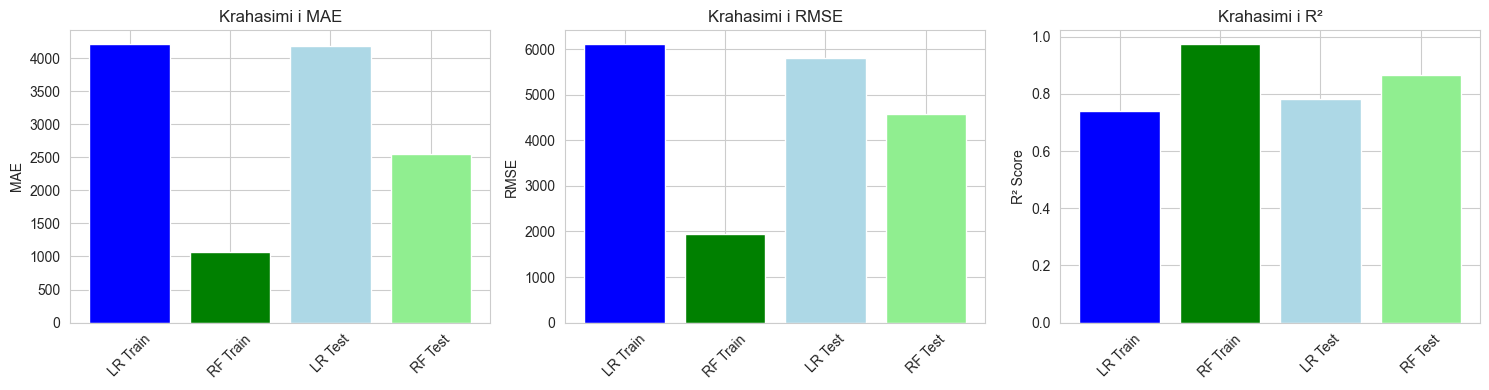

In [36]:
# Visualizim i krahasimit
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# MAE Comparison
axes[0].bar(['LR Train', 'RF Train', 'LR Test', 'RF Test'],
            [lr_train_metrics['MAE'], rf_train_metrics['MAE'],
             lr_test_metrics['MAE'], rf_test_metrics['MAE']],
            color=['blue', 'green', 'lightblue', 'lightgreen'])
axes[0].set_ylabel('MAE')
axes[0].set_title('Krahasimi i MAE')
axes[0].tick_params(axis='x', rotation=45)

# RMSE Comparison
axes[1].bar(['LR Train', 'RF Train', 'LR Test', 'RF Test'],
            [lr_train_metrics['RMSE'], rf_train_metrics['RMSE'],
             lr_test_metrics['RMSE'], rf_test_metrics['RMSE']],
            color=['blue', 'green', 'lightblue', 'lightgreen'])
axes[1].set_ylabel('RMSE')
axes[1].set_title('Krahasimi i RMSE')
axes[1].tick_params(axis='x', rotation=45)

# R² Comparison
axes[2].bar(['LR Train', 'RF Train', 'LR Test', 'RF Test'],
            [lr_train_metrics['R2'], rf_train_metrics['R2'],
             lr_test_metrics['R2'], rf_test_metrics['R2']],
            color=['blue', 'green', 'lightblue', 'lightgreen'])
axes[2].set_ylabel('R² Score')
axes[2].set_title('Krahasimi i R²')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 8. Vizualizimi i Parashikimeve

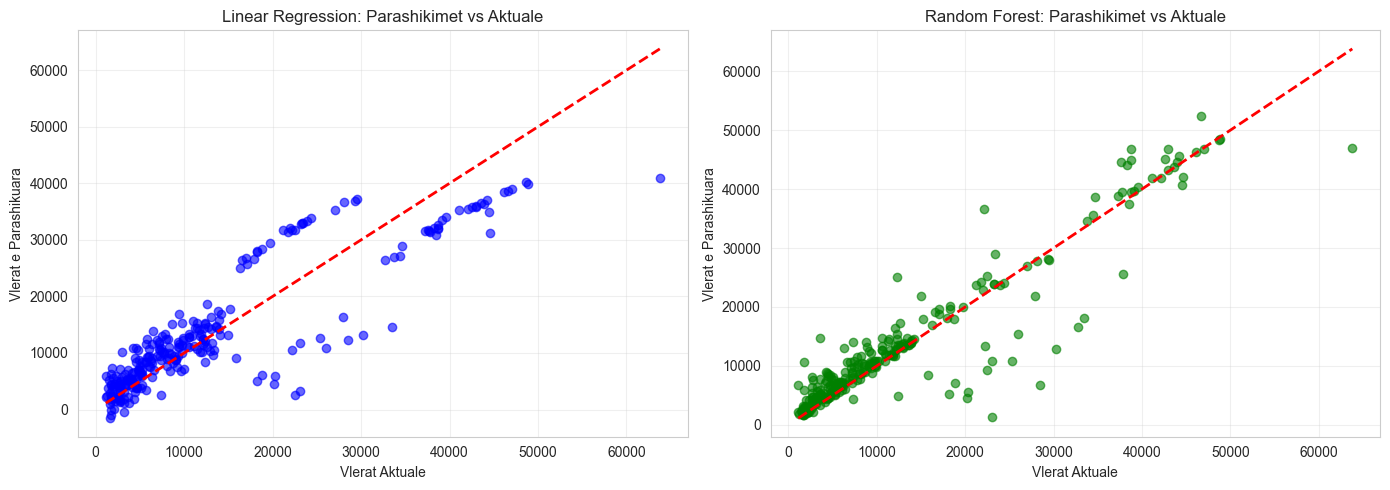

In [37]:
# Parashikimet vs Vlerat Aktuale - Linear Regression
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_test_pred_lr, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Vlerat Aktuale')
plt.ylabel('Vlerat e Parashikuara')
plt.title('Linear Regression: Parashikimet vs Aktuale')
plt.grid(True, alpha=0.3)

# Parashikimet vs Vlerat Aktuale - Random Forest
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_test_pred_rf, alpha=0.6, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Vlerat Aktuale')
plt.ylabel('Vlerat e Parashikuara')
plt.title('Random Forest: Parashikimet vs Aktuale')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Analiza e Gabimeve (Residuals)

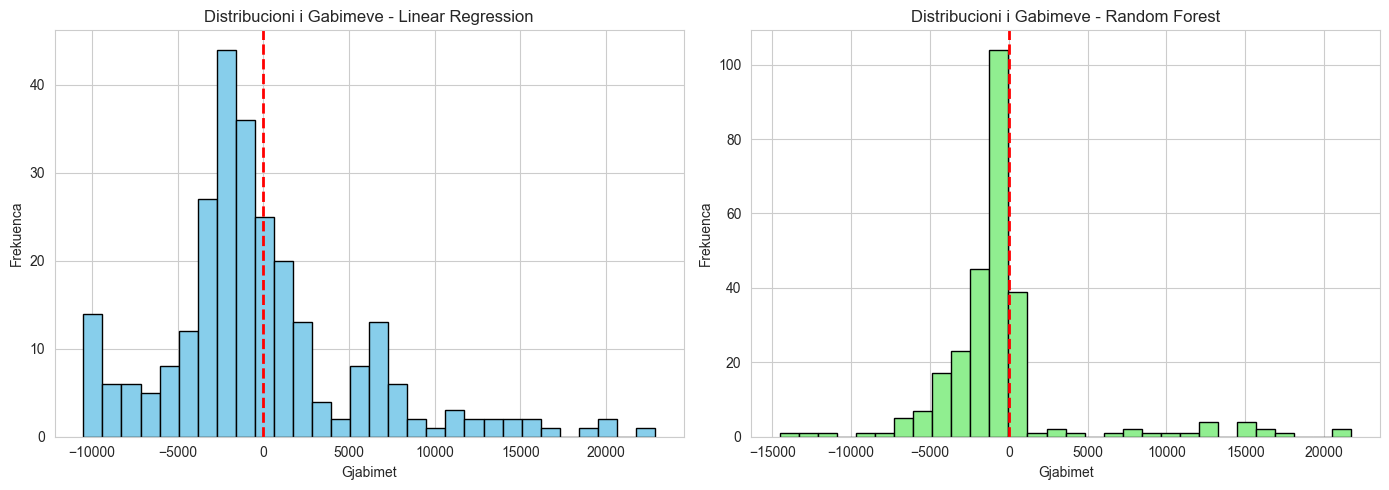

Mesatarja e Gabimeve (LR): -219.8309
Devijimi Standard i Gabimeve (LR): 5803.22

Mesatarja e Gabimeve (RF): -482.7583
Devijimi Standard i Gabimeve (RF): 4553.91


In [38]:
# Gjabimet për Linear Regression
residuals_lr = y_test - y_test_pred_lr

# Gjabimet për Random Forest
residuals_rf = y_test - y_test_pred_rf

plt.figure(figsize=(14, 5))

# Distribucioni i Gabimeve - Linear Regression
plt.subplot(1, 2, 1)
plt.hist(residuals_lr, bins=30, edgecolor='black', color='skyblue')
plt.xlabel('Gjabimet')
plt.ylabel('Frekuenca')
plt.title('Distribucioni i Gabimeve - Linear Regression')
plt.axvline(x=0, color='r', linestyle='--', lw=2)

# Distribucioni i Gabimeve - Random Forest
plt.subplot(1, 2, 2)
plt.hist(residuals_rf, bins=30, edgecolor='black', color='lightgreen')
plt.xlabel('Gjabimet')
plt.ylabel('Frekuenca')
plt.title('Distribucioni i Gabimeve - Random Forest')
plt.axvline(x=0, color='r', linestyle='--', lw=2)

plt.tight_layout()
plt.show()

print(f"Mesatarja e Gabimeve (LR): {residuals_lr.mean():.4f}")
print(f"Devijimi Standard i Gabimeve (LR): {residuals_lr.std():.2f}")
print(f"\nMesatarja e Gabimeve (RF): {residuals_rf.mean():.4f}")
print(f"Devijimi Standard i Gabimeve (RF): {residuals_rf.std():.2f}")

## 10. Interpretimi i Rezultateve

### Përfundimet Kryesore:

1. **Zgjedhja e Modelit të Mirë:**
   - Random Forest modeli tregon performance më të mirë në test set (R² më i lartë)
   - Kjo sugjeron që marrëdhëniet midis features dhe targetit janë më komplekse dhe jo-lineare

2. **Features më të Rëndësishme (sipas Random Forest):**
   - Shikoni tabelën "Rëndësia e Features" për të parë variablat më ndikues
   - Zakonisht "smoker" dhe "age" janë midis më të rëndësishmëve

3. **Interpretimet e Modelit:**
   - Personi me sigurimin shëndetsor paguan më shumë nëse: 
     - Është më i vjetër (age)
     - Peshon më shumë (BMI)
     - Është duhanpirës (smoker)
     - Ka fëmijë (children)

4. **Cilësia e Modelit:**
   - R² score tregon se sa mirë modeli shpjegon variacionin në target variable
   - RMSE dhe MAE tregojnë gabimin mesatar të parashikimit në njësi të parave

5. **Përgatitja e të dhënave:**
   - Nuk kishin vlera të munguara
   - Variablave kategorikë u janë dhënë vlera numerike përmes enkodimit
   - Shkallëzimi standard u aplikua për Linear Regression

In [39]:
# Parashikim për një klient të ri
print("\n" + "="*60)
print("SHEMBULL: Parashikim për një Klient të Ri")
print("="*60)

# Shembull klienti: 35-vjeçar, 28 BMI, 0 fëmijë, jo duhanpirës, në region northeast
new_client = pd.DataFrame({
    'age': [35],
    'bmi': [28],
    'children': [0],
    'smoker': [0],  # jo duhanpirës
    'sex_male': [1],  # mashkull
    'region_northwest': [0],
    'region_southeast': [0],
    'region_southwest': [0]
})

pred_lr = lr_model.predict(scaler.transform(new_client))[0]
pred_rf = rf_model.predict(new_client)[0]

print(f"\nKlienti i ri:")
print(f"  - Mosha: 35 vite")
print(f"  - BMI: 28")
print(f"  - Fëmijë: 0")
print(f"  - Duhanpirës: Jo")
print(f"  - Gjinia: Mashkull")
print(f"  - Rajoni: Northeast")

print(f"\nParashikimet:")
print(f"  - Linear Regression: ${pred_lr:,.2f}")
print(f"  - Random Forest: ${pred_rf:,.2f}")
print(f"  - Mesatarja: ${(pred_lr + pred_rf) / 2:,.2f}")


SHEMBULL: Parashikim për një Klient të Ri

Klienti i ri:
  - Mosha: 35 vite
  - BMI: 28
  - Fëmijë: 0
  - Duhanpirës: Jo
  - Gjinia: Mashkull
  - Rajoni: Northeast

Parashikimet:
  - Linear Regression: $6,481.77
  - Random Forest: $4,771.46
  - Mesatarja: $5,626.61
